# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
dataframe = pd.read_csv("data/advertising.csv")
dataframe = dataframe.loc[:, 'TV':]
dataframe

,TV,radio,newpaper,sales
0,230.1,37.8,6s9.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0
...,...,...,...,...
195,38.2,3.7,13.8,7600.0
196,94.2,4.9,8.1,9700.0
197,177.0,9.3,6.4,12800.0
198,283.6,42.0,66.2,25500.0


## Exploratory Data Analysis 

In [4]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   TV        200 non-null    float64
 1   radio     200 non-null    float64
 2   newpaper  200 non-null    str    
 3   sales     200 non-null    float64
dtypes: float64(3), str(1)
memory usage: 7.1 KB


In [10]:
fila_con_error = dataframe[
    pd.to_numeric(dataframe["newpaper"], errors="coerce").isna()
]
print(fila_con_error)

      TV  radio  newpaper    sales
0  230.1   37.8       NaN  22100.0


In [11]:
dataframe.loc[0, "newpaper"] = 69.2

# Y ahora ya puedes convertir toda la columna a float sin problemas
dataframe["newpaper"] = dataframe["newpaper"].astype(float)

In [12]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   TV        200 non-null    float64
 1   radio     200 non-null    float64
 2   newpaper  200 non-null    float64
 3   sales     200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [14]:
dataframe.head()

,TV,radio,newpaper,sales
0,230.1,37.8,69.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0


In [13]:
dataframe.describe()

,TV,radio,newpaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14022.500000
std,85.854236,14.846809,21.778621,5217.456566
min,0.700000,0.000000,0.300000,1600.000000
25%,74.375000,9.975000,12.750000,10375.000000
50%,149.750000,22.900000,25.750000,12900.000000
75%,218.825000,36.525000,45.100000,17400.000000
max,296.400000,49.600000,114.000000,27000.000000


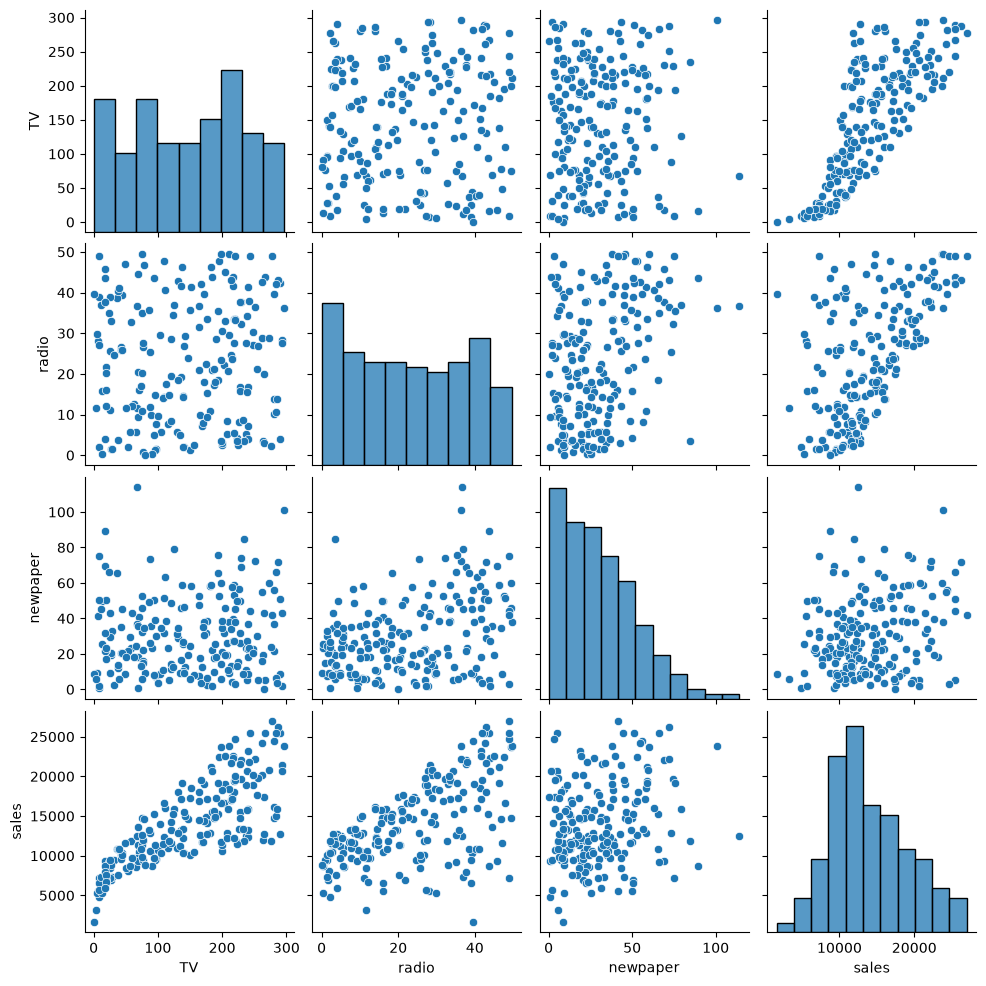

In [15]:
sns.pairplot(dataframe);

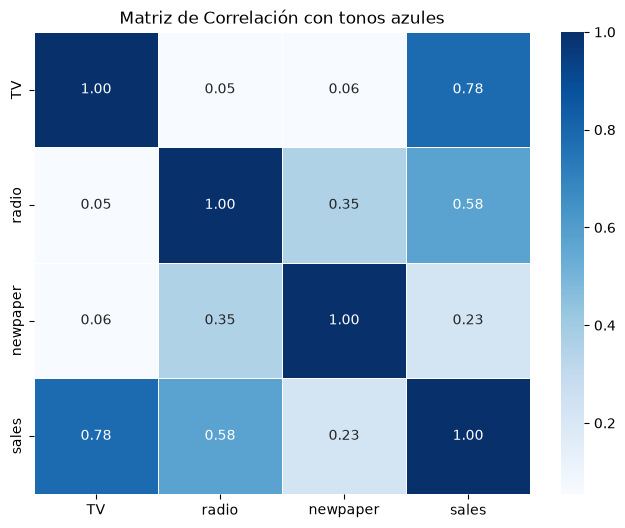

In [17]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    dataframe.corr(), annot=True, cmap="Blues", fmt=".2f", linewidths=0.5
)
plt.title("Matriz de Correlación con tonos azules")
plt.show()

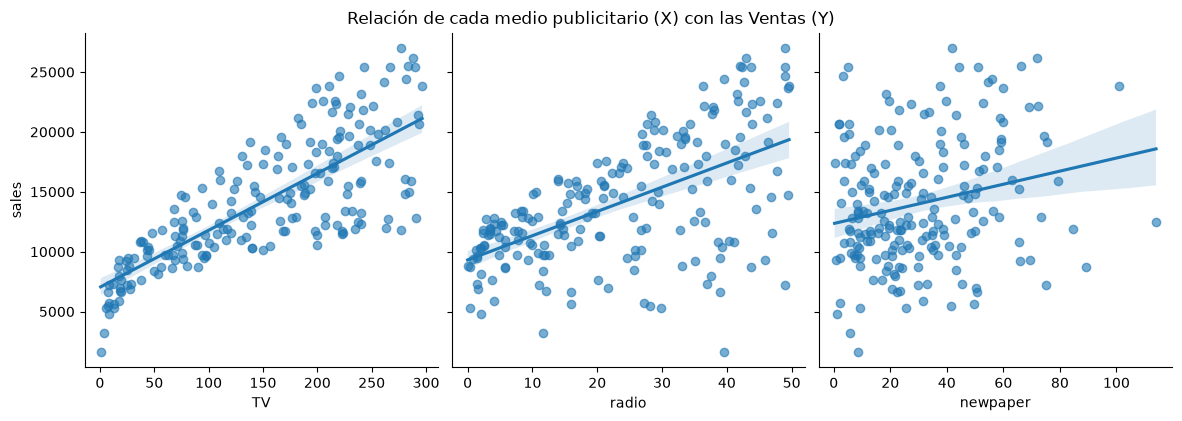

In [21]:
sns.pairplot(
    dataframe,  # Asegúrate de que se llama 'dataframe' o cambia por tu variable (ej. df)
    x_vars=["TV", "radio", "newpaper"],
    y_vars="sales",
    kind="reg",
    height=4,
    aspect=1,
    plot_kws=dict(
        scatter_kws=dict(alpha=0.6)
    ),  # <-- Así es como se pasa la transparencia ahora
)

plt.suptitle(
    "Relación de cada medio publicitario (X) con las Ventas (Y)", y=1.03
)
plt.show()

## Modelado

In [26]:
from sklearn.model_selection import train_test_split

# 1. Separar características (X) y objetivo (y) por nombre de columna (mucho más seguro)
X = dataframe[["TV", "radio", "newpaper"]]  # o también: dataframe.drop(columns=['sales'])
y = dataframe["sales"]

# 2. Dividir automáticamente (por ejemplo, 70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [52]:
from sklearn.preprocessing import StandardScaler

# 1. Inicializar el escalador
scaler = StandardScaler()

# 2. Ajustar ('fit') y transformar los datos de entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# 3. Transformar únicamente los datos de test (usando lo que aprendió del train)
X_test_scaled = scaler.transform(X_test)

print("Primeras filas de X_train escalado:")
print(X_train_scaled[:5])

Primeras filas de X_train escalado:
[[ 1.53003874 -0.8862929  -1.16598019]
 [ 0.34103865 -0.17314426 -0.40960132]
 [-0.5202089  -0.42000341  0.39526337]
 [-1.58600275  0.79372072  1.71892638]
 [ 1.60659408 -1.33201081 -1.06415995]]


In [53]:
# 1. Entrenar el modelo con los datos escalados
model_marketing_scaled = LinearRegression()
model_marketing_scaled.fit(X_train_scaled, y_train)

# 2. Predicciones y evaluación usando test escalado
predictions_scaled = model_marketing_scaled.predict(X_test_scaled)

print(f"R2 Score (Escalado): {r2_score(y_test, predictions_scaled):.4f}")
print(
    f"MAE (Error Medio Absoluto): {mean_absolute_error(y_test, predictions_scaled):.4f}"
)

# 3. Coeficientes (¡Ahora sí son 100% comparables entre sí!)
for col, coef in zip(X.columns, model_marketing_scaled.coef_):
  print(f"Coeficiente {col} (Escalado): {coef:.4f}")
print(f"Intercepto: {model_marketing_scaled.intercept_:.4f}")

R2 Score (Escalado): 0.8609
MAE (Error Medio Absoluto): 1511.6692
Coeficiente TV (Escalado): 3683.3408
Coeficiente radio (Escalado): 2906.2524
Coeficiente newpaper (Escalado): 141.9477
Intercepto: 14497.1429


el R2 score significa que el marketing explica la gran mayoría de por qué se vende más o menos cada mes.
El MAE, En promedio, las previsiones mensuales de la empresa se desviarán en unas 1,511 unidades
Coef Radio : Es, por mucho, el canal que mayor retorno está dando por cada euro invertido en este dataset.
Coef TV : Tiene un impacto sólido y constante
Coef Newpaper : Su coeficiente es casi cero. Esto le dice a la empresa que invertir en periódicos apenas aporta ventas.

In [54]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Pipeline completo: Escala -> Polinomios -> Regresión Lineal
poly_model_scaled = make_pipeline(
    StandardScaler(), PolynomialFeatures(degree=2), LinearRegression()
)

# Entrenar el modelo (aquí le pasas tus X_train originales y él las escala solo)
poly_model_scaled.fit(X_train, y_train)

# Predecir y evaluar (aplica automáticamente el mismo escalado al test)
poly_predictions_scaled = poly_model_scaled.predict(X_test)

print("--- REGRESIÓN POLINÓMICA ESCALADA (Grado 2) ---")
print(f"R2 Score: {r2_score(y_test, poly_predictions_scaled):.4f}")
print(
    f"MAE (Error Medio Absoluto): {mean_absolute_error(y_test, poly_predictions_scaled):.4f}"
)

--- REGRESIÓN POLINÓMICA ESCALADA (Grado 2) ---
R2 Score: 0.9808
MAE (Error Medio Absoluto): 590.5975


El R2 Score es más alto: El modelo ahora es capaz de explicar el 98.1% de la variabilidad de las ventas!
El MAE significa que la previsión mensual de la empresa ahora se equivocará, en promedio, por poco más de 590 unidades/euros en lugar de 1,500.

### Modelos Polinómicos

In [55]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# 1. Ridge Polinómico CON ESCALADOR
ridge_poly_scaled = make_pipeline(
    StandardScaler(), PolynomialFeatures(degree=2), Ridge(alpha=1.0)
)
ridge_poly_scaled.fit(X_train, y_train)
ridge_preds = ridge_poly_scaled.predict(X_test)

print("--- RIDGE POLINÓMICO (Escalado) ---")
print(f"R2 Score: {r2_score(y_test, ridge_preds):.4f}")
print(f"MAE (Error Medio Absoluto): {mean_absolute_error(y_test, ridge_preds):.4f}")

# 2. Lasso Polinómico CON ESCALADOR
lasso_poly_scaled = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2),
    Lasso(alpha=1.0, max_iter=10000),
)
lasso_poly_scaled.fit(X_train, y_train)
lasso_preds = lasso_poly_scaled.predict(X_test)

print("\n--- LASSO POLINÓMICO (Escalado) ---")
print(f"R2 Score: {r2_score(y_test, lasso_preds):.4f}")
print(f"MAE (Error Medio Absoluto): {mean_absolute_error(y_test, lasso_preds):.4f}")

--- RIDGE POLINÓMICO (Escalado) ---
R2 Score: 0.9808
MAE (Error Medio Absoluto): 590.4238

--- LASSO POLINÓMICO (Escalado) ---
R2 Score: 0.9810
MAE (Error Medio Absoluto): 589.3864


Estabilidad total: Que Ridge y Lasso den prácticamente el mismo resultado que la regresión polinómica estándar con alpha=1.0 significa que tus datos están muy limpios y el modelo de grado 2 no está sufriendo de sobreajuste (overfitting). El modelo es robusto.

Precisión sobresaliente: Explicar el 98.1% de las ventas con un error promedio de solo ~590 unidades es un éxito.

El modelo definitivo: La Regresión Polinómica

## Resultados

In [57]:
import pandas as pd

# Imagina que el próximo mes van a invertir:
# TV: 230, Radio: 37.8, Periódico: 69.2 (ejemplo de datos nuevos)
nuevo_mes = pd.DataFrame(
    {"TV": [230.0], "radio": [37.8], "newpaper": [69.2]}  # <-- Corregido aquí
)

# Usamos el modelo polinómico que ya entrenamos (por ejemplo, el Lasso o Ridge)
prediccion_ventas = lasso_poly.predict(nuevo_mes)

print(f"💰 Ventas estimadas para el próximo mes: {prediccion_ventas[0]:.2f}")

💰 Ventas estimadas para el próximo mes: 21760.79


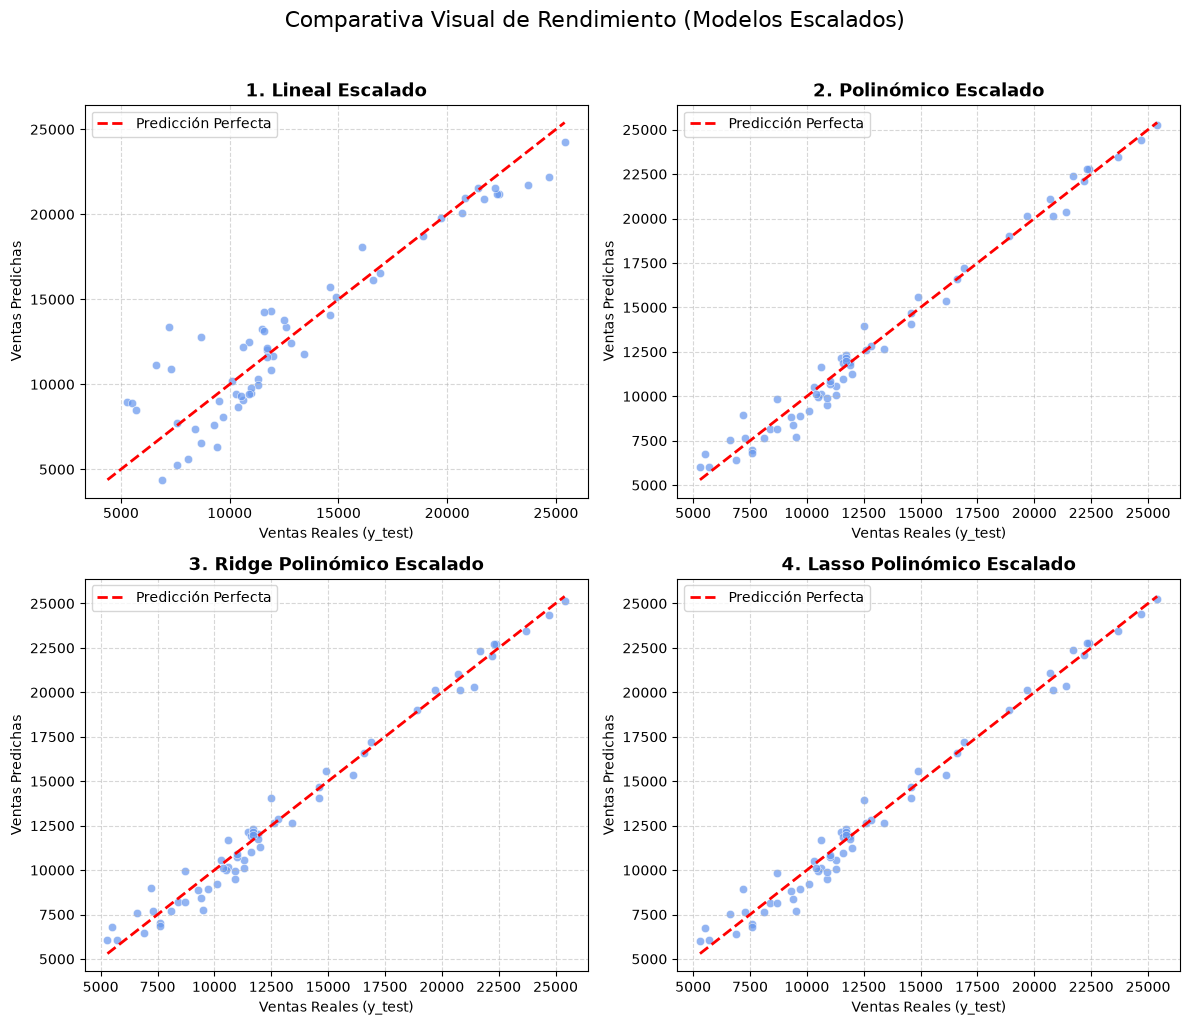

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# 1. Definimos y entrenamos los modelos con el escalador integrado
models = {
    "1. Lineal Escalado": make_pipeline(StandardScaler(), LinearRegression()),
    "2. Polinómico Escalado": make_pipeline(
        StandardScaler(), PolynomialFeatures(degree=2), LinearRegression()
    ),
    "3. Ridge Polinómico Escalado": make_pipeline(
        StandardScaler(), PolynomialFeatures(degree=2), Ridge(alpha=1.0)
    ),
    "4. Lasso Polinómico Escalado": make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2),
        Lasso(alpha=1.0, max_iter=10000),
    ),
}

for model in models.values():
  model.fit(X_train, y_train)

# 2. Generamos la matriz de gráficos (2x2)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
  preds = model.predict(X_test)

  # Dispersión de Real vs Predicho
  sns.scatterplot(
      x=y_test, y=preds, ax=axes[i], alpha=0.7, color="cornflowerblue"
  )

  # Línea diagonal de predicción perfecta (y = x)
  min_val = min(y_test.min(), preds.min())
  max_val = max(y_test.max(), preds.max())
  axes[i].plot(
      [min_val, max_val],
      [min_val, max_val],
      "r--",
      lw=2,
      label="Predicción Perfecta",
  )

  # Estilos
  axes[i].set_title(name, fontsize=13, fontweight="bold")
  axes[i].set_xlabel("Ventas Reales (y_test)", fontsize=10)
  axes[i].set_ylabel("Ventas Predichas", fontsize=10)
  axes[i].legend(loc="upper left")
  axes[i].grid(True, linestyle="--", alpha=0.5)

plt.suptitle(
    "Comparativa Visual de Rendimiento (Modelos Escalados)", fontsize=16, y=1.02
)
plt.tight_layout()
plt.show()

In [61]:
from sklearn.metrics import mean_absolute_error

# 1. Calcular los errores usando los modelos con StandardScaler integrado
baseline_error = mean_absolute_error(
    y_test, model_marketing_scaled.predict(X_test)
)
poly_error = mean_absolute_error(y_test, poly_model_scaled.predict(X_test))
ridge_error = mean_absolute_error(y_test, ridge_poly_scaled.predict(X_test))
lasso_error = mean_absolute_error(y_test, lasso_poly_scaled.predict(X_test))

# 2. Imprimir resultados
print("Linear regression error (escalado):     %0.4f" % baseline_error)
print("Polynomial regression error (escalado): %0.4f" % poly_error)
print("Ridge polynomial error (escalado):      %0.4f" % ridge_error)
print("Lasso polynomial error (escalado):      %0.4f" % lasso_error)

Linear regression error (escalado):     533072.5616
Polynomial regression error (escalado): 590.5975
Ridge polynomial error (escalado):      590.4238
Lasso polynomial error (escalado):      589.3864


c:\Users\haize\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


In [63]:
import pandas as pd

# Imagina que el próximo mes van a invertir:
# TV: 230, Radio: 37.8, Periódico: 69.2 (ejemplo de datos nuevos)
nuevo_mes = pd.DataFrame(
    {"TV": [230.0], "radio": [37.8], "newpaper": [69.2]}  # <-- Corregido aquí
)

# Usamos el modelo polinómico que ya entrenamos
prediccion_ventas = lasso_poly.predict(nuevo_mes)

print(f"💰 Ventas estimadas para el próximo mes: {prediccion_ventas[0]:.2f}")

💰 Ventas estimadas para el próximo mes: 21760.79


In [65]:
import pandas as pd

# 1. Generamos las predicciones con el modelo escalado
poly_predictions_scaled = poly_model_scaled.predict(X_test)

# 2. Creamos un DataFrame para comparar los valores reales y las predicciones
df_comparacion = pd.DataFrame(
    {"Real (y_test)": y_test.values, "Predicho": poly_predictions_scaled}
)

# 3. Añadimos una columna con la diferencia absoluta (el error en cada caso)
df_comparacion["Diferencia (Error)"] = abs(
    df_comparacion["Real (y_test)"] - df_comparacion["Predicho"]
)

# 4. Mostramos las primeras 10 filas
print(df_comparacion.head(10))

   Real (y_test)      Predicho  Diferencia (Error)
0        16900.0  17222.638053          322.638053
1        22400.0  22764.319419          364.319419
2        21400.0  20342.403109         1057.596891
3         7300.0   7638.230805          338.230805
4        24700.0  24430.702122          269.297878
5        12600.0  12626.709065           26.709065
6        22300.0  22775.810253          475.810253
7         8400.0   8172.573079          227.426921
8        11500.0  12143.459497          643.459497
9        14900.0  15592.957740          692.957740


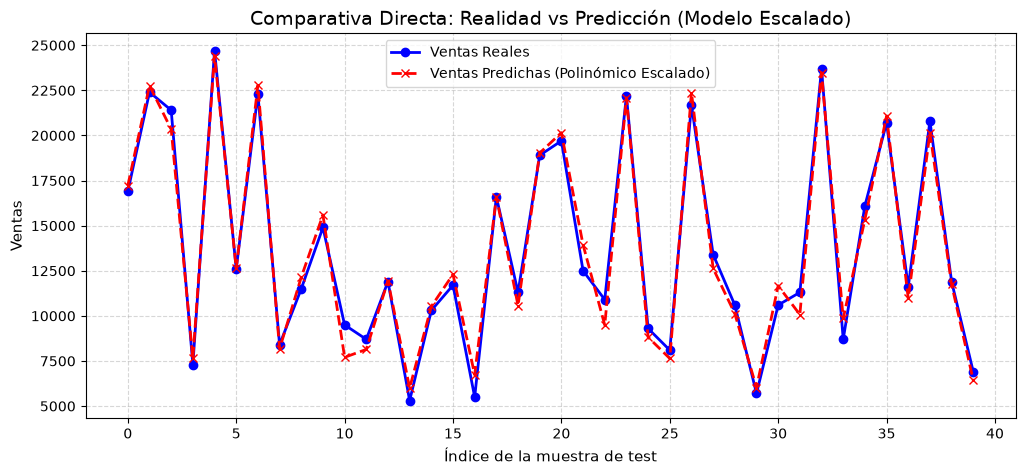

In [66]:
import matplotlib.pyplot as plt

# 1. Generamos las predicciones con el modelo escalado
poly_predictions_scaled = poly_model_scaled.predict(X_test)

# 2. Creamos el gráfico (limitado a los primeros 40 puntos para que se vea claro)
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.values[:40],
    label="Ventas Reales",
    marker="o",
    color="blue",
    linewidth=2,
)
plt.plot(
    poly_predictions_scaled[:40],
    label="Ventas Predichas (Polinómico Escalado)",
    marker="x",
    color="red",
    linestyle="--",
    linewidth=2,
)

plt.title(
    "Comparativa Directa: Realidad vs Predicción (Modelo Escalado)", fontsize=14
)
plt.xlabel("Índice de la muestra de test", fontsize=11)
plt.ylabel("Ventas", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()